# 03 Retrieval (B3)

**What this does.** Ranks every training company as a comp for each target and picks the comp list.
- **B3 similarity:** for each facet, 0.5 x MPNet embedding cosine + 0.5 x TF-IDF cosine (BM25 IDF); facets are
  combined with information weights (how much a facet says, saturated). Company size is out; "none" is missing.
- **Current variant "Sonnet + Fiona sub-sector"** (Eric): the Sonnet general facets plus Fiona's sub-sector as one
  more facet. Barbara's 293 reviewed pairs (rounds 2-3) come from this list.
- **Comp list:** mutual top 10 (each is in the other's top 10), topped up to 3 from the one-way list. The pool is
  the 373 training companies; holdout companies never enter it.

**Saved outputs:** `outputs-local/v1a/03_retrieval/` (`selector_candidates/` is the current list;
`facet_add_drop/` the facet add/drop experiment).

**Changelog**
- 2026-11-18: created from `v1/notebooks/similarity_methods.ipynb` and the add/drop experiment
  (`b3_facet_add_drop.py`). `method1_candidates.py` now builds the current variant from `current.toml` and
  reproduces the saved list. The add/drop experiment no longer reads v1's Sol grades of holdout pairs by default
  (`--v1-holdout-diagnostic` reproduces v1's table).

In [1]:
import sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "v1a" / "current.toml").exists())
sys.path.insert(0, str(ROOT / "v1a" / "common"))
import paths, nbtools as nb
paths.setup()
import pandas as pd
pd.set_option("display.width", 160); pd.set_option("display.max_colwidth", 90); pd.set_option("display.max_rows", 80)
cur = paths.current()
checks = nb.Checks()

## 1. Current setting (`v1a/current.toml`)

In [2]:
pd.Series(cur["retrieval"])

method                                                             B3
variant                                     Sonnet + Fiona sub-sector
rule                                    mutual top 10, topped up to 3
excluded_facets                                        [company_size]
candidates         outputs-local/v1a/03_retrieval/selector_candidates
dtype: object

## 2. Inputs

In [3]:
import glob
addrop = Path(sorted(glob.glob(str(paths.out("03_retrieval") / "facet_add_drop" / "2*")))[-1])
cand = paths.path(cur["retrieval"]["candidates"])
nb.inputs([cur["profiles"]["general"], cur["profiles"]["sector"], cur["universe"]["split"],
           cur["retrieval"]["candidates"] + "/candidates.csv", cur["retrieval"]["candidates"] + "/ranking.csv.gz",
           str((addrop / "metrics.csv").relative_to(ROOT).as_posix())])

,input,rows,sha256,status
0,outputs-local/v1a/02_profiles/facets_sonnet/tables/facets.csv,533,8619ecf21c32,matches seed
1,outputs-local/v1a/02_profiles/sector_facets_sonnet/tables/sector_facets.csv,533,a7139d71efd6,matches seed
2,outputs-local/v1a/01_universe/split/split.csv,533,0de7aa335563,matches seed
3,outputs-local/v1a/03_retrieval/selector_candidates/candidates.csv,3730,1544b96bfc27,matches seed
4,outputs-local/v1a/03_retrieval/selector_candidates/ranking.csv.gz,138756,54aab1c701d6,matches seed
5,outputs-local/v1a/03_retrieval/facet_add_drop/20261118T225043Z/metrics.csv,180,5863b8078695,new in v1a


## 3. Results

### 3.1 Build the current B3 lists

In [4]:
import method1_candidates as mc, facet_weighting as fw
ranking, top, run, S, ids = mc.build()
sel = top[top["selected"]]
per = sel.groupby("target").size()
print(f"variant {run['variant']}: {run['n_targets']} targets, {len(sel)} selected pairs; "
      f"comps per target median {per.median():.0f}, min {per.min()}, max {per.max()}")
print("facets combined:", ", ".join(run["facets"]))
pd.Series({"mutual top-10 comps": int(sel["mutual"].sum()), "topped up to reach 3": int(sel["topped_up"].sum())}).to_frame("pairs")

variant Sonnet + Fiona sub-sector: 373 targets, 2538 selected pairs; comps per target median 7, min 3, max 10
facets combined: offering_description, primary_products, primary_services, customer_segment, end_markets, revenue_model, value_chain_position, geography_served, specialization, distribution_channels, regulatory_exposure, Fiona sub-sector


,pairs
mutual top-10 comps,2492
topped up to reach 3,46


In [5]:
per.value_counts().sort_index().rename("targets with this many comps").to_frame().T

,3,4,5,6,7,8,9,10
targets with this many comps,53,31,32,42,50,54,49,62


### 3.2 Two examples (the round-1 golden-set targets)

In [6]:
for t in ["PCTY", "WEN"]:
    rows = top[(top["target_ticker"] == t)][["rank", "comp_ticker", "similarity", "mutual", "topped_up", "selected"]]
    print(t); display(rows.round(3))

PCTY


,rank,comp_ticker,similarity,mutual,topped_up,selected
2530,1,ASUR,0.705,True,False,True
2531,2,PAYC,0.684,True,False,True
2532,3,ADP,0.630,True,False,True
2533,4,ALIT,0.519,True,False,True
2534,5,BBSI,0.404,True,False,True
2535,6,UPLD,0.379,False,False,False
2536,7,INTU,0.365,True,False,True
2537,8,CXM,0.359,False,False,False
2538,9,SSNC,0.346,False,False,False
2539,10,BLKB,0.343,True,False,True


WEN


,rank,comp_ticker,similarity,mutual,topped_up,selected
3350,1,BROS,0.454,True,False,True
3351,2,TXRH,0.453,True,False,True
3352,3,STKS,0.421,True,False,True
3353,4,HQI,0.360,True,False,True
3354,5,PLNT,0.342,True,False,True
3355,6,BDL,0.341,True,False,True
3356,7,LW,0.335,True,False,True
3357,8,GSHD,0.313,False,False,False
3358,9,BGS,0.311,False,False,False
3359,10,INN,0.306,False,False,False


### 3.3 Facet add/drop (Eric, v1a run without holdout labels)

Each variant changes one facet source or bundle; the rule is fixed. `human_majority` is the 32-pair round-1 majority
set (PCTY, WEN); `haiku_screen_diagnostic` is the saved Haiku screen (a model, not people). Unlabeled pairs are never
negatives.

In [7]:
metrics = pd.read_csv(addrop / "metrics.csv")
show = ["B3 Haiku", "B3 Sonnet", "Sonnet + Fiona sub-sector", "Sonnet + Fiona categories", "Sonnet + Barbara SIC2 facets",
        "Sonnet + FF49", "Sonnet + SIC4", "Sonnet + all additions"]
cols = ["pairwise_accuracy", "good_recall", "direct_recall", "labeled_bad_selected"]
table = metrics[metrics["variant"].isin(show) & metrics["label_source"].isin(["human_majority", "haiku_screen_diagnostic"])]
table.pivot(index="variant", columns="label_source", values=cols).reindex(show).round(3)

pairwise_accuracy                            good_recall                          direct_recall                 \
label_source                 haiku_screen_diagnostic human_majority haiku_screen_diagnostic human_majority haiku_screen_diagnostic human_majority   
variant                                                                                                                                             
B3 Haiku                                       0.938          0.982                   0.961          1.000                     NaN            1.0   
B3 Sonnet                                      0.936          0.939                   0.953          0.909                     NaN            1.0   
Sonnet + Fiona sub-sector                      0.935          0.947                   0.958          0.909                     NaN            1.0   
Sonnet + Fiona categories                      0.937          0.956                   0.946          0.909                     NaN            1.0   
Sonnet + Barbara SIC2 facets                   0.931          0.939                   0.944          0.909                     NaN            1.0   
Sonnet + FF49                                  0.899          0.886                   0.878          0.818                     NaN            1.0   
Sonnet + SIC4                                  0.915          0.912                   0.902          0.727                     NaN            1.0   
Sonnet + all additions                         0.895          0.877                   0.856          0.727                     NaN            1.0   

                                labeled_bad_selected                 
label_source                 haiku_screen_diagnostic human_majority  
variant                                                              
B3 Haiku                                      1532.0            0.0  
B3 Sonnet                                     1357.0            1.0  
Sonnet + Fiona sub-sector                     1409.0            1.0  
Sonnet + Fiona categories                     1348.0            1.0  
Sonnet + Barbara SIC2 facets                  1360.0            1.0  
Sonnet + FF49                                 1184.0            0.0  
Sonnet + SIC4                                 1236.0            0.0  
Sonnet + all additions                        1179.0            0.0

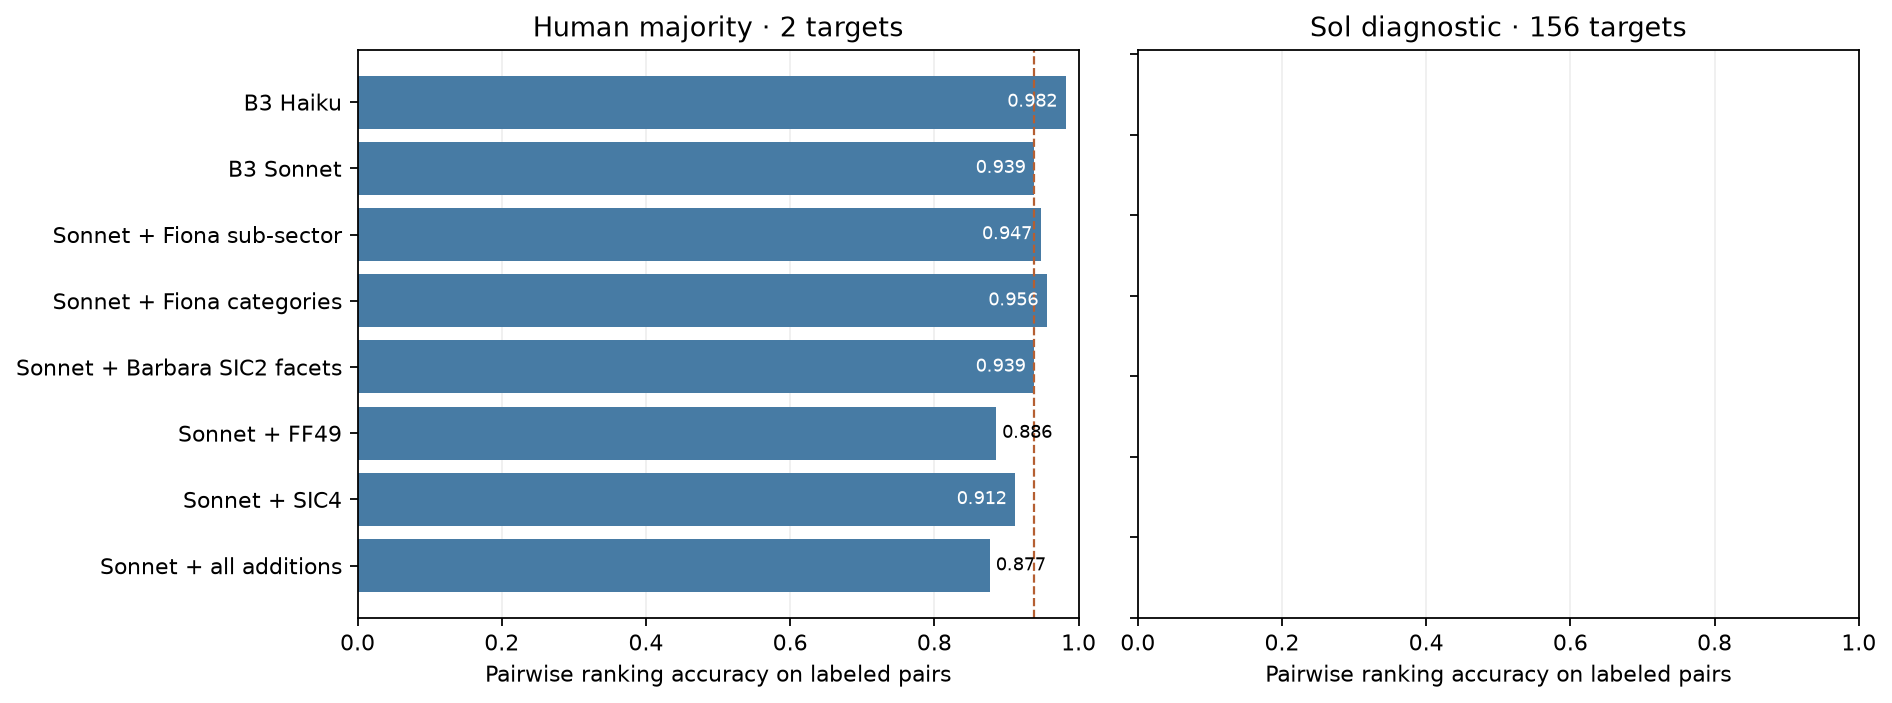

In [8]:
from IPython.display import Image
Image(filename=str(addrop / "pairwise_accuracy.png"), width=900)

## 4. Checks against the saved v1 numbers

In [9]:
saved = pd.read_csv(cand / "candidates.csv", dtype={"target": str, "comp": str})
saved_rank = pd.read_csv(cand / "ranking.csv.gz", dtype={"target": str, "comp": str})
a = set(zip(saved.loc[saved["selected"], "target"], saved.loc[saved["selected"], "comp"]))
b = set(zip(sel["target"], sel["comp"]))
checks.add("selected comp lists identical to the saved list", a == b and len(a) == 2538, f"{len(b)} pairs")
m = ranking.merge(saved_rank, on=["target", "comp"], suffixes=("", "_saved"))
diff = float((m["similarity"] - m["similarity_saved"]).abs().max())
checks.add("similarities match (max difference < 1e-6)", len(m) == len(saved_rank) and diff < 1e-6, f"{diff:.1e} over {len(m)} pairs")
moved = m[m["rank"] != m["rank_saved"]]
ties = all(((ranking["target"] == r.target) & ((ranking["similarity"] - r.similarity).abs() < 1e-7)).sum() >= 2 for r in moved.itertuples())
checks.add("rank differences are exact ties outside the top 10", ties and (moved["rank"] > fw.TOP_K).all(), f"{len(moved)} rows")
v1_eval = pd.read_csv(paths.out("03_retrieval") / "facet_add_drop_eval" / "metrics.csv")
v1_eval = v1_eval[v1_eval["label_source"] != "sol_holdout_diagnostic"].reset_index(drop=True)
num = v1_eval.select_dtypes("number").columns
same = v1_eval[["variant", "label_source"]].equals(metrics[["variant", "label_source"]]) and \
       float((v1_eval[num] - metrics[num]).abs().max().max()) == 0
checks.add("add/drop metrics equal v1's (without the holdout rows)", same, f"{len(metrics)} rows")
checks.show()

4/4 checks pass


,check,result,detail
0,selected comp lists identical to the saved list,pass,2538 pairs
1,similarities match (max difference < 1e-6),pass,1.1e-07 over 138756 pairs
2,rank differences are exact ties outside the top 10,pass,10 rows
3,add/drop metrics equal v1's (without the holdout rows),pass,180 rows


## 5. History (v1)

- `v1/notebooks/similarity_methods.ipynb` (2026-11-03/04) compared v0's cosine with method 1 (= B3) and method 2
  (FAME-inspired gates); method 2 was about method 1. B3 became the v1 baseline on comp quality. It also replaced
  v0's z >= 2 rule with the mutual top 10, and made "none" missing.
- The add/drop experiment (2026-11-05) produced the current list: on the 32 majority pairs Haiku B3 selects 11/11
  good and 0 bad, Sonnet B3 10/11 and 1 bad; Fiona's sub-sector leaves those counts unchanged.
- The 11-10 integration study ran 20 retrieval rules on three facet sources; it stays in v1 (index in `09_analysis`).
- Valuation comparisons of these lists belong to `08_valuation`.